## Dự đoán hành vi mua sắm trực tuyến so với mua sắm tại cửa hàng

**Dataset:** Tập dữ liệu hành vi mua sắm trực tuyến so với mua sắm tại cửa hàng
**Shape:** 11,789 rows x 25 columns
**Target:** `shopping_preference` — 3 classes: `Online`, `Store`, `Hybrid`
**Task:** Phân loại đa lớp có giám sát


---
## 1. Vấn đề

### Bối cảnh
Hiểu được cách khách hàng thích mua sắm trực tuyến, tại cửa hàng truyền thống, hay kết hợp cả hai - là một thách thức quan trọng đối với các nhà bán lẻ hiện đại. Dự đoán chính xác sở thích mua sắm cho phép tiếp thị cá nhân hóa, lập kế hoạch tồn kho tốt hơn và cải thiện trải nghiệm khách hàng

### Bài toán
Cho dữ liệu nhân khẩu học và hành vi dạng bảng của 11.789 khách hàng, hãy xây dựng một mô hình đa lớp dự đoán
`shopping_preference` có 3 kết quả xảy ra:
- **Online** — khách hàng chủ yếu mua sắm trực tuyến
- **Store** — khách hàng chủ yếu mua sắm tại cửa hàng truyền thống
- **Hybrid** — khách hàng mua sắm cả hai

### Mục tiêu
`shopping_preference` — mã hóa:
- `0` = Hybrid
- `1` = Online
- `2` = Store

### Chỉ số đánh giá
Accuracy, Precision, Recall, F1-Score (weighted and macro), and per-class metrics.

### Machine learning
Supervised Learning — Multi-class Classification (3 classes)

---
## 2. Dataset Overview

The dataset contains 11,789 customer records and 25 columns:

| Column | Type | Description |
|---|---|---|
| `age` | numeric | Customer age |
| `monthly_income` | numeric | Monthly income |
| `daily_internet_hours` | numeric | Hours online per day |
| `smartphone_usage_years` | numeric | Years using smartphones |
| `social_media_hours` | numeric | Hours on social media per day |
| `online_payment_trust_score` | numeric | Trust in online payments (1-10) |
| `tech_savvy_score` | numeric | Technical proficiency score |
| `monthly_online_orders` | numeric | Online orders per month |
| `monthly_store_visits` | numeric | Physical store visits per month |
| `avg_online_spend` | numeric | Average monthly online spend |
| `avg_store_spend` | numeric | Average monthly store spend |
| `discount_sensitivity` | numeric | Sensitivity to discounts |
| `return_frequency` | numeric | How often returns are made |
| `avg_delivery_days` | numeric | Average delivery days experienced |
| `delivery_fee_sensitivity` | numeric | Sensitivity to delivery fees |
| `free_return_importance` | numeric | Importance placed on free returns |
| `product_availability_online` | numeric | Satisfaction with online availability |
| `impulse_buying_score` | numeric | Tendency for impulse purchases |
| `need_touch_feel_score` | numeric | Preference to physically inspect products |
| `brand_loyalty_score` | numeric | Brand loyalty level |
| `environmental_awareness` | numeric | Environmental concern score |
| `time_pressure_level` | numeric | Perceived time pressure |
| `gender` | categorical | Gender (Male, Female, Other) |
| `city_tier` | categorical | City tier classification |
| `shopping_preference` | categorical | **Target variable** (Online/Store/Hybrid) |

---
## 3. Environment Setup and Data Loading

This section imports all required libraries, loads the dataset, and performs an initial inspection.

### 3.1 Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os
warnings.filterwarnings('ignore')

from sklearn.preprocessing  import StandardScaler, LabelEncoder
from sklearn.model_selection import (
    train_test_split, cross_val_score,
    StratifiedKFold, GridSearchCV
)

from sklearn.linear_model    import LogisticRegression
from sklearn.tree            import DecisionTreeClassifier
from sklearn.ensemble        import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors       import KNeighborsClassifier
from xgboost                 import XGBClassifier
from sklearn.metrics         import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size']      = 12

import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

### 3.2 Load Dataset

In [2]:
df = pd.read_csv("dataset.csv")

# ── Define target and feature columns ──────────────────────
TARGET      = 'shopping_preference'
CAT_COLS    = ['gender', 'city_tier']
NUM_COLS    = [c for c in df.columns if c not in [TARGET] + CAT_COLS]

print(f'\nDataset shape : {df.shape}')
print(f'Target column : {TARGET}')
print(f'Unique classes: {sorted(df[TARGET].unique())}')


Dataset shape : (11789, 25)
Target column : shopping_preference
Unique classes: ['Hybrid', 'Online', 'Store']


### 3.3 Encode Target Variable
**shopping_preference -> integer label** -
Hybrid = 0 | Online = 1 | Store = 2

In [3]:
le_target = LabelEncoder()
df['target'] = le_target.fit_transform(df[TARGET])

class_mapping = dict(zip(le_target.classes_,
                          le_target.transform(le_target.classes_)))
print('Class encoding:', class_mapping)
print('\nClass distribution:')
print(df['target'].value_counts().rename(
    index={v:k for k,v in class_mapping.items()}
))

Class encoding: {'Hybrid': np.int64(0), 'Online': np.int64(1), 'Store': np.int64(2)}

Class distribution:
target
Store     10244
Online     1176
Hybrid      369
Name: count, dtype: int64


### 3.4 Initial Data Inspection

In [4]:
print('Shape:', df.shape)
display(df.head())

Shape: (11789, 26)


,age,monthly_income,daily_internet_hours,smartphone_usage_years,social_media_hours,online_payment_trust_score,tech_savvy_score,monthly_online_orders,monthly_store_visits,avg_online_spend,...,product_availability_online,impulse_buying_score,need_touch_feel_score,brand_loyalty_score,environmental_awareness,time_pressure_level,gender,city_tier,shopping_preference,target
0,56,221111,6.5,12,0.7,1,6,16,16,28551,...,7,1,3,6,5,2,Other,Tier 3,Store,2
1,69,96029,8.2,13,2.7,6,9,14,1,124056,...,4,9,6,8,1,7,Male,Tier 3,Hybrid,0
2,46,19055,6.4,4,2.1,10,8,2,0,81939,...,10,1,1,3,3,3,Female,Tier 3,Store,2
3,32,53170,6.4,11,0.7,2,10,20,3,35901,...,2,4,8,2,6,6,Female,Tier 1,Store,2
4,60,244016,6.0,5,0.7,2,5,18,16,131971,...,5,8,9,7,1,6,Male,Tier 3,Store,2


In [5]:
# Numerical summary
df[NUM_COLS].describe()

,age,monthly_income,daily_internet_hours,smartphone_usage_years,social_media_hours,online_payment_trust_score,tech_savvy_score,monthly_online_orders,monthly_store_visits,avg_online_spend,...,return_frequency,avg_delivery_days,delivery_fee_sensitivity,free_return_importance,product_availability_online,impulse_buying_score,need_touch_feel_score,brand_loyalty_score,environmental_awareness,time_pressure_level
count,11789.000000,11789.000000,11789.000000,11789.000000,11789.000000,11789.000000,11789.000000,11789.000000,11789.000000,11789.000000,...,11789.00000,11789.000000,11789.000000,11789.000000,11789.000000,11789.000000,11789.000000,11789.000000,11789.000000,11789.000000
mean,48.729409,131704.282382,6.011367,7.597930,2.514471,5.498770,5.534312,24.677581,9.482144,74554.929341,...,4.46747,3.999661,5.468827,5.462041,5.518704,5.486386,5.485368,5.532021,5.448554,5.504114
std,17.899445,68120.726684,1.976811,4.011628,1.263047,2.880366,2.887251,14.431277,5.728825,43167.126595,...,2.88545,1.995881,2.870195,2.882177,2.867613,2.877918,2.877264,2.848796,2.872740,2.876561
min,18.000000,15005.000000,1.000000,1.000000,0.000000,1.000000,1.000000,0.000000,0.000000,523.000000,...,0.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,33.000000,72450.000000,4.600000,4.000000,1.600000,3.000000,3.000000,12.000000,5.000000,36797.000000,...,2.00000,2.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
50%,49.000000,131916.000000,6.000000,8.000000,2.500000,5.000000,6.000000,25.000000,9.000000,74859.000000,...,4.00000,4.000000,5.000000,5.000000,6.000000,5.000000,5.000000,6.000000,5.000000,6.000000
75%,64.000000,190505.000000,7.400000,11.000000,3.400000,8.000000,8.000000,37.000000,14.000000,112134.000000,...,7.00000,6.000000,8.000000,8.000000,8.000000,8.000000,8.000000,8.000000,8.000000,8.000000
max,79.000000,249989.000000,12.000000,14.000000,6.000000,10.000000,10.000000,49.000000,19.000000,149996.000000,...,9.00000,7.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000


In [6]:
# Categorical summary
df[CAT_COLS + [TARGET]].describe()

,gender,city_tier,shopping_preference
count,11789,11789,11789
unique,3,3,3
top,Male,Tier 1,Store
freq,3966,3982,10244


---
## 4. Data Preprocessing

Các bước gồm :
- Phân tích và điền giá trị thiếu
- Loại bỏ hàng trùng lặp
- Phát hiện và xử lý ngoại lệ
- Mã hóa biến phân loại
- Kiểm tra cân bằng lớp mục tiêu

### 4.1 Phân tích


No missing values found in the dataset.


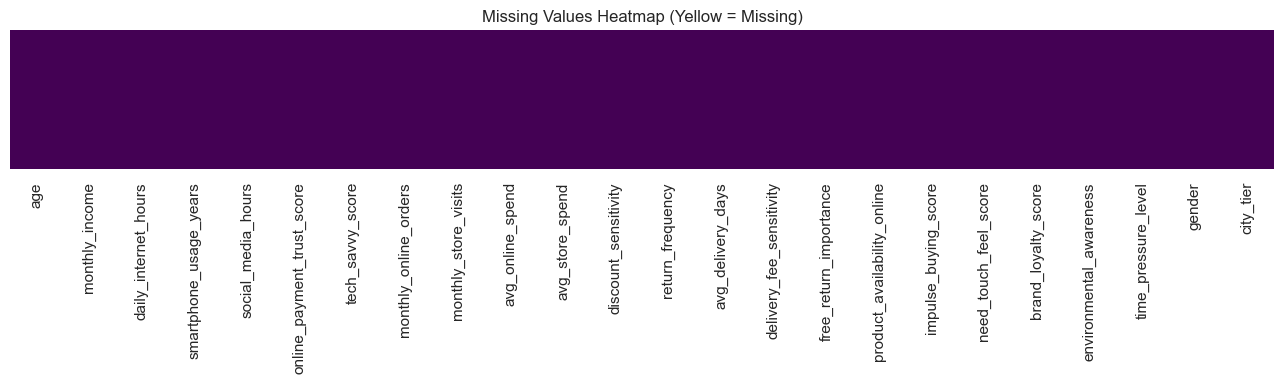

In [7]:
missing_count = df[NUM_COLS + CAT_COLS].isnull().sum()
missing_pct   = (missing_count / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Count'         : missing_count,
    'Missing Percentage (%)': missing_pct.round(2)
}).query('`Missing Count` > 0')   .sort_values('Missing Percentage (%)', ascending=False)

if missing_df.empty:
    print('No missing values found in the dataset.')
else:
    print('Columns with missing values:')
    display(missing_df)

plt.figure(figsize=(13, 4))
sns.heatmap(df[NUM_COLS + CAT_COLS].isnull(),
            cbar=False, yticklabels=False, cmap='viridis')
plt.title('Missing Values Heatmap (Yellow = Missing)')
plt.tight_layout()
plt.show()

### 4.2 Điền giá trị thiếu
**Numerical  -> median** - Categorical -> mode

In [8]:
for col in NUM_COLS:
    if df[col].isnull().sum() > 0:
        med = df[col].median()
        df[col].fillna(med, inplace=True)
        print(f'  Numeric  imputed: {col} <- median = {med:.3f}')

for col in CAT_COLS:
    if df[col].isnull().sum() > 0:
        mode_val = df[col].mode()[0]
        df[col].fillna(mode_val, inplace=True)
        print(f'  Categoric imputed: {col} <- mode = {mode_val}')

print('Total remaining missing values:', df[NUM_COLS + CAT_COLS].isnull().sum().sum())

Total remaining missing values: 0


### 4.3 Loại bỏ hàng trùng

In [9]:
dups = df.duplicated(subset=NUM_COLS + CAT_COLS).sum()
print(f'Duplicate rows found: {dups}')

if dups > 0:
    df.drop_duplicates(subset=NUM_COLS + CAT_COLS, inplace=True)
    df.reset_index(drop=True, inplace=True)
    print(f'Duplicates removed. New shape: {df.shape}')
else:
    print('No duplicate rows. Dataset is clean.')

Duplicate rows found: 0
No duplicate rows. Dataset is clean.


### 4.4 Xử lý ngoại lệ

  daily_internet_hours: 25 values capped

Total outlier values treated: 25


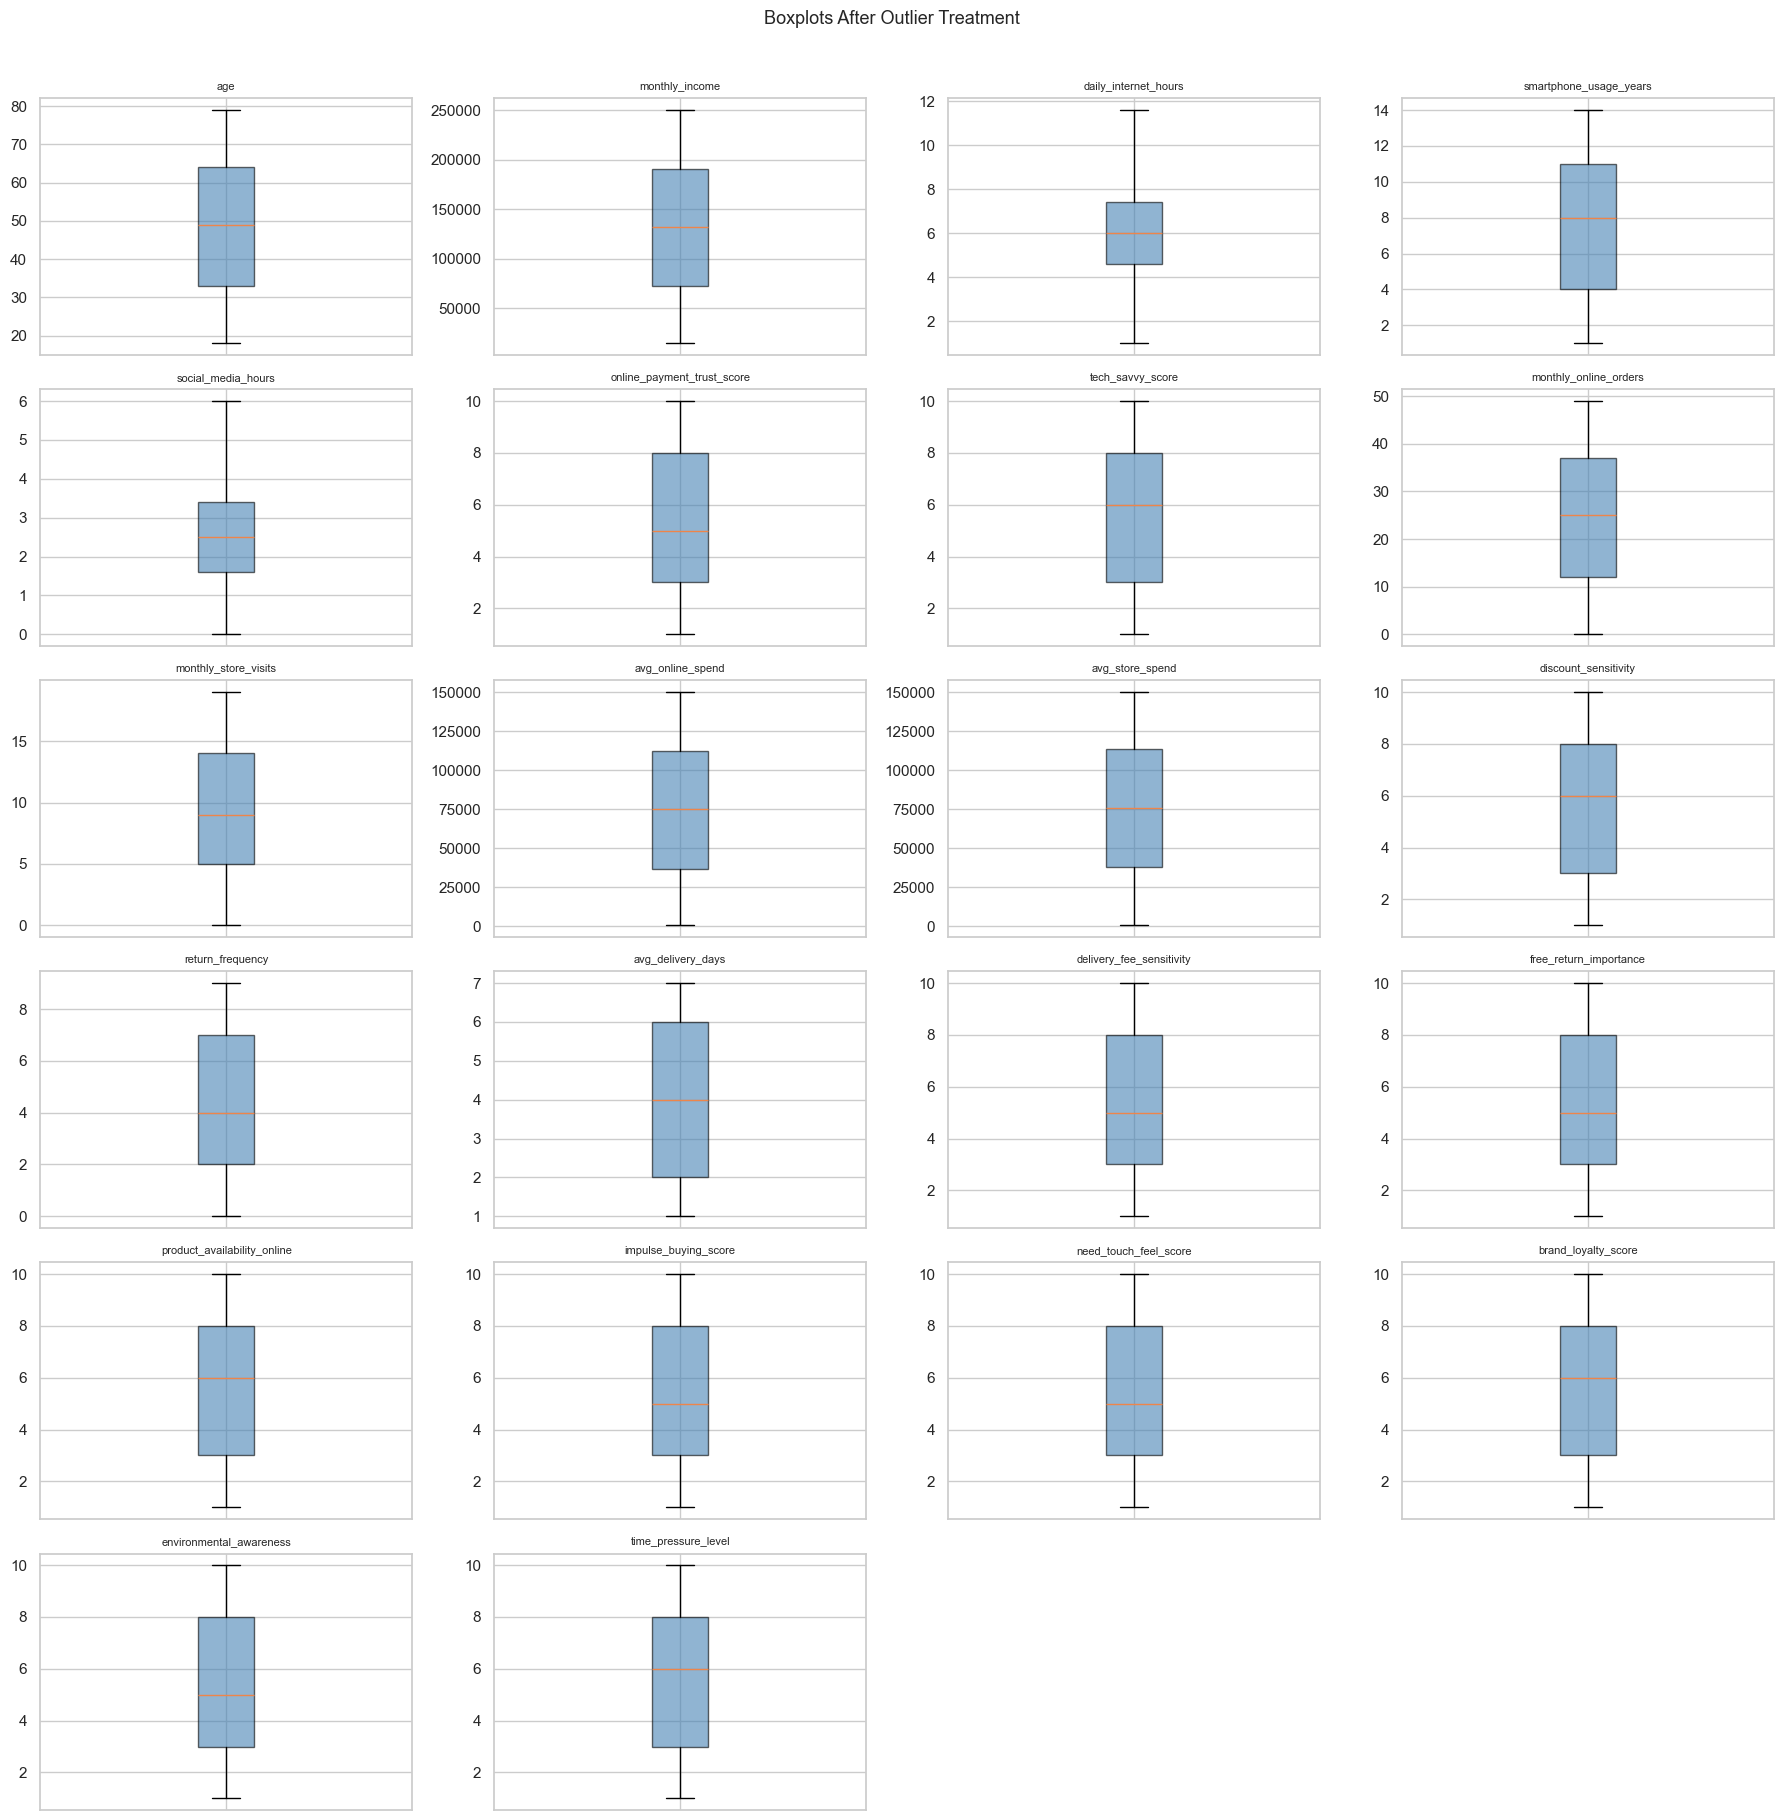

In [10]:
def cap_outliers_iqr(data, col):
    Q1, Q3 = data[col].quantile(0.25), data[col].quantile(0.75)
    IQR    = Q3 - Q1
    lo, hi = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n      = ((data[col] < lo) | (data[col] > hi)).sum()
    data[col] = data[col].clip(lo, hi)
    return n

total_outliers = 0
for col in NUM_COLS:
    n = cap_outliers_iqr(df, col)
    if n > 0:
        print(f'  {col}: {n} values capped')
    total_outliers += n

print(f'\nTotal outlier values treated: {total_outliers}')

# Boxplots after treatment
n_cols_plot = 4
n_rows_plot = (len(NUM_COLS) + n_cols_plot - 1) // n_cols_plot
fig, axes   = plt.subplots(n_rows_plot, n_cols_plot,
                            figsize=(18, n_rows_plot * 3))
axes = axes.flatten()

for i, col in enumerate(NUM_COLS):
    axes[i].boxplot(df[col].dropna(), patch_artist=True,
                    boxprops=dict(facecolor='steelblue', alpha=0.6))
    axes[i].set_title(col, fontsize=8)
    axes[i].tick_params(axis='x', labelbottom=False)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Boxplots After Outlier Treatment', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

### 4.5 Kiểm tra số lớp của mục tiêu

In [ ]:
class_counts = df['target'].value_counts().sort_index()
class_labels = [f'{k} ({v})' for v, k in class_mapping.items()]

print('Class distribution:')
for label, count in zip(class_labels, class_counts.values):
    pct = (count / len(df)) * 100
    print(f'  {label}: {count} khách hàng ({pct:.1f}%)')

Class distribution:
  0 (Hybrid): 369 khách hàng (3.1%)
  1 (Online): 1176 khách hàng (10.0%)
  2 (Store): 10244 khách hàng (86.9%)


### 4.6 Mã hóa one_hot cho đặc trưng phân loại

In [12]:
print('Categorical columns to encode:', CAT_COLS)
for col in CAT_COLS:
    print(f'  {col}: {sorted(df[col].unique().tolist())}')

df_encoded = pd.get_dummies(df, columns=CAT_COLS, drop_first=True)

# Convert boolean columns to int
bool_cols = df_encoded.select_dtypes(include='bool').columns
df_encoded[bool_cols] = df_encoded[bool_cols].astype(int)

print('\nShape before encoding:', df.shape)
print('Shape after  encoding:', df_encoded.shape)
display(df_encoded.head(3))

Categorical columns to encode: ['gender', 'city_tier']
  gender: ['Female', 'Male', 'Other']
  city_tier: ['Tier 1', 'Tier 2', 'Tier 3']

Shape before encoding: (11789, 26)
Shape after  encoding: (11789, 28)


,age,monthly_income,daily_internet_hours,smartphone_usage_years,social_media_hours,online_payment_trust_score,tech_savvy_score,monthly_online_orders,monthly_store_visits,avg_online_spend,...,need_touch_feel_score,brand_loyalty_score,environmental_awareness,time_pressure_level,shopping_preference,target,gender_Male,gender_Other,city_tier_Tier 2,city_tier_Tier 3
0,56,221111,6.5,12,0.7,1,6,16,16,28551,...,3,6,5,2,Store,2,0,1,0,1
1,69,96029,8.2,13,2.7,6,9,14,1,124056,...,6,8,1,7,Hybrid,0,1,0,0,1
2,46,19055,6.4,4,2.1,10,8,2,0,81939,...,1,3,3,3,Store,2,0,0,0,1


---
## 5. Xây dựng và lựa chọn đặc trưng

Phần này xây dựng các đặc trưng thông tin mới, xếp hạng tất cả các đặc trưng theo tầm quan trọng và chọn tập con phù hợp nhất để xây dựng mô hình.

### 6.1 Đặc trưng mới

In [13]:
df_fe = df.copy()

# Online vs Store spend ratio
df_fe['online_store_spend_ratio'] = (
    df_fe['avg_online_spend'] /
    (df_fe['avg_store_spend'].replace(0, np.nan))
).round(4)

# Online vs Store visit ratio
df_fe['online_store_order_ratio'] = (
    df_fe['monthly_online_orders'] /
    (df_fe['monthly_store_visits'].replace(0, np.nan))
).round(4)

# Total monthly spend
df_fe['total_monthly_spend'] = (
    df_fe['avg_online_spend'] + df_fe['avg_store_spend']
)

# Digital engagement index: combines internet use, social media, tech savvy
df_fe['digital_engagement_index'] = (
    df_fe['daily_internet_hours'] +
    df_fe['social_media_hours'] +
    df_fe['tech_savvy_score']
).round(2)

# Physical preference index: combines need to touch/feel and store visits
df_fe['physical_preference_index'] = (
    df_fe['need_touch_feel_score'] + df_fe['monthly_store_visits']
).round(2)

# Income per age (purchasing power proxy)
df_fe['income_per_age'] = (
    df_fe['monthly_income'] / df_fe['age'].replace(0, np.nan)
).round(2)

new_features = ['online_store_spend_ratio', 'online_store_order_ratio',
                'total_monthly_spend', 'digital_engagement_index',
                'physical_preference_index', 'income_per_age']

# Fill any NaN introduced by division
for col in new_features:
    df_fe[col].fillna(df_fe[col].median(), inplace=True)

print('New features created:')
for f in new_features:
    print(f'  {f}')

# Re-encode categorical columns
df_model = pd.get_dummies(df_fe, columns=CAT_COLS, drop_first=True)
bool_c   = df_model.select_dtypes(include='bool').columns
df_model[bool_c] = df_model[bool_c].astype(int)

print('\nShape after feature engineering + encoding:', df_model.shape)

New features created:
  online_store_spend_ratio
  online_store_order_ratio
  total_monthly_spend
  digital_engagement_index
  physical_preference_index
  income_per_age

Shape after feature engineering + encoding: (11789, 34)


### 6.2 Chuẩn bị dữ liệu 

In [ ]:
label_map = {v: k for k, v in class_mapping.items()}

DROP_COLS = [TARGET, 'target', 'shopping_preference']
X_full    = df_model.drop(columns=[c for c in DROP_COLS if c in df_model.columns],
                           errors='ignore')

X_full    = X_full.select_dtypes(include=['int64','float64','uint8'])
X_full    = X_full.fillna(X_full.median(numeric_only=True))

y = df_model['target'].astype(int)

print('Feature matrix shape:', X_full.shape)
print('Target distribution:')
print(y.value_counts().rename(index=label_map))

Feature matrix shape: (11789, 32)
Target distribution:
target
Store     10244
Online     1176
Hybrid      369
Name: count, dtype: int64


### 6.3 Đánh giá tầm quan trọng của các đặc trưng thông qua thuật toán RandomForest

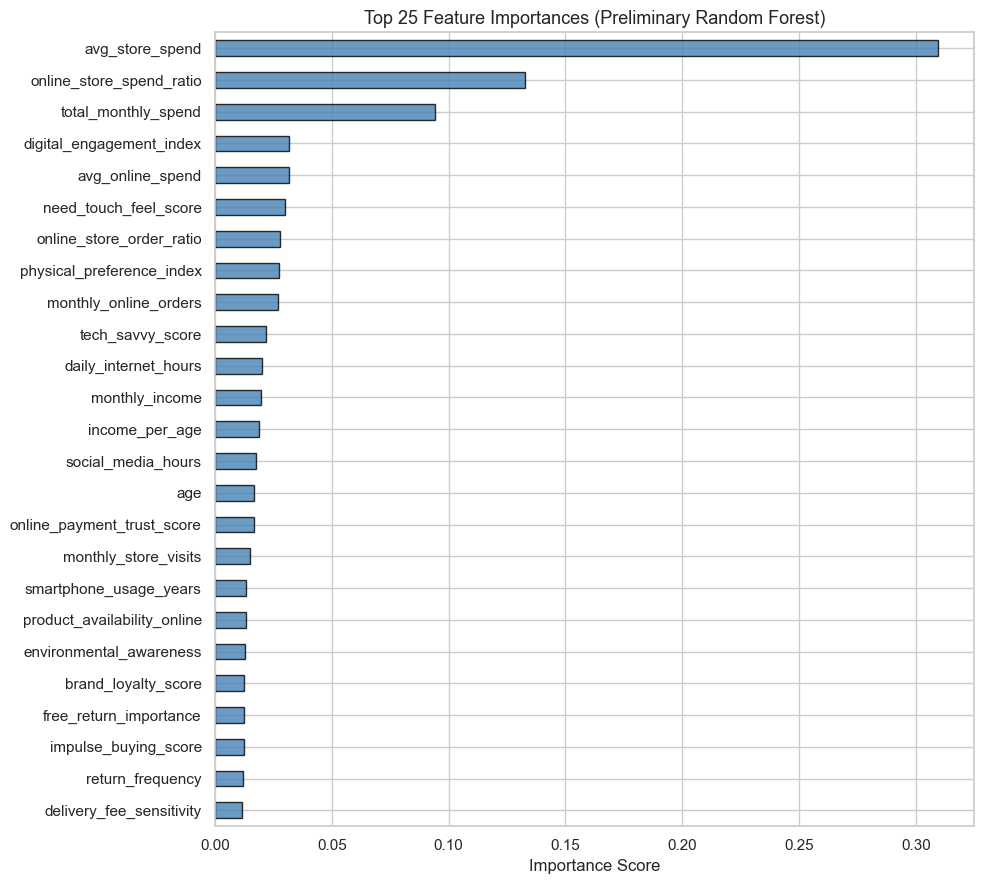

In [15]:
rf_prelim = RandomForestClassifier(
    n_estimators=150, random_state=RANDOM_STATE,
    class_weight='balanced', n_jobs=-1
)
rf_prelim.fit(X_full, y)

feat_imp = pd.Series(
    rf_prelim.feature_importances_, index=X_full.columns
).sort_values(ascending=False)

top_n = min(25, len(feat_imp))
plt.figure(figsize=(10, 9))
feat_imp.head(top_n).sort_values().plot(
    kind='barh', color='steelblue', edgecolor='black', alpha=0.8
)
plt.title(f'Top {top_n} Feature Importances (Preliminary Random Forest)', fontsize=13)
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

### 6.4 Chọn các đặc tính và xây dựng dữ liệu train model

In [ ]:
# đặt ngưỡng vượt qua là 0.01
imp_threshold     = 0.01
selected_features = feat_imp[feat_imp >= imp_threshold].index.tolist()

print(f'Features selected (importance >= {imp_threshold}): {len(selected_features)}')
print(selected_features)

X = X_full[selected_features]

# Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print('\nTraining set:', X_train.shape)
print('Test set:    ', X_test.shape)
print('\nTrain class balance:')
print(y_train.value_counts().rename(index=label_map))
print('\nTest class balance:')
print(y_test.value_counts().rename(index=label_map))

Features selected (importance >= 0.01): 27
['avg_store_spend', 'online_store_spend_ratio', 'total_monthly_spend', 'digital_engagement_index', 'avg_online_spend', 'need_touch_feel_score', 'online_store_order_ratio', 'physical_preference_index', 'monthly_online_orders', 'tech_savvy_score', 'daily_internet_hours', 'monthly_income', 'income_per_age', 'social_media_hours', 'age', 'online_payment_trust_score', 'monthly_store_visits', 'smartphone_usage_years', 'product_availability_online', 'environmental_awareness', 'brand_loyalty_score', 'free_return_importance', 'impulse_buying_score', 'return_frequency', 'delivery_fee_sensitivity', 'time_pressure_level', 'discount_sensitivity']

Training set: (9431, 27)
Test set:     (2358, 27)

Train class balance:
target
Store     8195
Online     941
Hybrid     295
Name: count, dtype: int64

Test class balance:
target
Store     2049
Online     235
Hybrid      74
Name: count, dtype: int64


### 6.5 Điều chỉnh tỷ lệ đặc trưng

Được dùng cho các mô hình dựa trên khoảng cách (LR, KNN) và các mô hình dựa trên cây sử dụng các giá trị chưa được điều chỉnh tỷ lệ

In [17]:
scaler         = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

SCALED_MODELS = ['Logistic Regression', 'K-Nearest Neighbours']
print('StandardScaler applied.')

StandardScaler applied.


---
## 6. Huấn luyện mô hình

Sáu thuật toán phân loại được huấn luyện bằng phương pháp Kiểm chéo phân lớp 5 phần (Stratified 5-Fold Cross-Validation), sau đó mô hình tốt nhất sẽ được tinh chỉnh thông qua GridSearchCV

### 6.1 Định nghĩa các mô hình

In [19]:
n_classes = len(class_mapping)

models = {
    'Logistic Regression' : LogisticRegression(
        max_iter=2000, random_state=RANDOM_STATE,
        class_weight='balanced'
    ),
    'K-Nearest Neighbours': KNeighborsClassifier(n_neighbors=7),
    'Decision Tree'       : DecisionTreeClassifier(
        max_depth=10, random_state=RANDOM_STATE, class_weight='balanced'
    ),
    'Random Forest'       : RandomForestClassifier(
        n_estimators=150, random_state=RANDOM_STATE,
        class_weight='balanced', n_jobs=-1
    ),
    'Gradient Boosting'   : GradientBoostingClassifier(
        n_estimators=100, random_state=RANDOM_STATE
    ),
    'XGBoost'             : XGBClassifier(
        n_estimators=150, use_label_encoder=False,
        objective='multi:softprob', num_class=n_classes,
        eval_metric='mlogloss', random_state=RANDOM_STATE, verbosity=0
    )
}

print('Models defined:', list(models.keys()))

Models defined: ['Logistic Regression', 'K-Nearest Neighbours', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'XGBoost']


### 6.2 Kiểm định chéo 5 lần phân tầng (Weighted F1)

In [20]:
cv         = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = {}

print('Running 5-Fold Cross-Validation...\n')

for name, model in models.items():
    X_cv   = X_train_scaled if name in SCALED_MODELS else X_train.values
    scores = cross_val_score(model, X_cv, y_train,
                             cv=cv, scoring='f1_weighted', n_jobs=-1)
    cv_results[name] = scores
    print(f'{name:<25} | Mean F1: {scores.mean():.4f} | Std: {scores.std():.4f}')

print('\nCross-validation complete.')

Running 5-Fold Cross-Validation...

Logistic Regression       | Mean F1: 0.9645 | Std: 0.0023
K-Nearest Neighbours      | Mean F1: 0.8765 | Std: 0.0058
Decision Tree             | Mean F1: 0.9175 | Std: 0.0049
Random Forest             | Mean F1: 0.9373 | Std: 0.0034
Gradient Boosting         | Mean F1: 0.9504 | Std: 0.0023
XGBoost                   | Mean F1: 0.9580 | Std: 0.0024

Cross-validation complete.


### 6.3 Bảng xếp hạng năng lực của 6 thuật toán

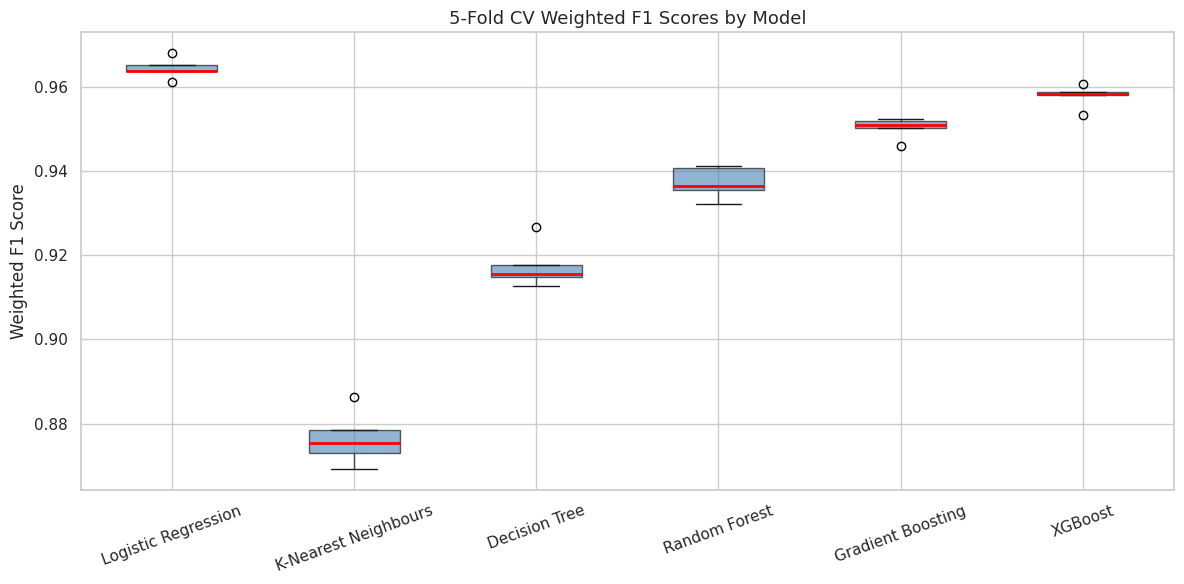

In [ ]:
cv_df = pd.DataFrame(cv_results)

plt.figure(figsize=(12, 6))

cv_df.boxplot(
    vert=True, patch_artist=True,
    boxprops=dict(facecolor='steelblue', alpha=0.6),
    medianprops=dict(color='red', linewidth=2)
)
plt.title('5-Fold CV Weighted F1 Scores by Model', fontsize=13)
plt.ylabel('Weighted F1 Score')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### 6.4 Điều chỉnh siêu tham số của mô hình tốt nhất (GridSearchCV)

In [22]:
mean_cv   = {k: v.mean() for k, v in cv_results.items()}
best_name = max(mean_cv, key=mean_cv.get)
print(f'Best model from CV: {best_name}  (Mean F1: {mean_cv[best_name]:.4f})')

param_grids = {
    'Random Forest': {
        'n_estimators'    : [100, 200],
        'max_depth'       : [None, 10, 20],
        'min_samples_split': [2, 5]
    },
    'XGBoost': {
        'n_estimators' : [100, 200],
        'max_depth'    : [3, 6],
        'learning_rate': [0.05, 0.1, 0.2]
    },
    'Gradient Boosting': {
        'n_estimators' : [100, 200],
        'max_depth'    : [3, 5],
        'learning_rate': [0.05, 0.1]
    },
    'Decision Tree': {
        'max_depth'        : [5, 10, 20, None],
        'min_samples_split': [2, 5, 10]
    },
    'Logistic Regression': {
        'C'     : [0.01, 0.1, 1, 10],
        'solver': ['lbfgs', 'saga']
    },
    'K-Nearest Neighbours': {
        'n_neighbors': [3, 5, 7, 11],
        'weights'    : ['uniform', 'distance']
    }
}

base_models = {
    'Random Forest'       : RandomForestClassifier(random_state=RANDOM_STATE,
                                                    class_weight='balanced', n_jobs=-1),
    'XGBoost'             : XGBClassifier(use_label_encoder=False,
                                          objective='multi:softprob',
                                          num_class=n_classes,
                                          eval_metric='mlogloss',
                                          random_state=RANDOM_STATE, verbosity=0),
    'Gradient Boosting'   : GradientBoostingClassifier(random_state=RANDOM_STATE),
    'Decision Tree'       : DecisionTreeClassifier(random_state=RANDOM_STATE,
                                                    class_weight='balanced'),
    'Logistic Regression' : LogisticRegression(max_iter=2000,
                                                class_weight='balanced',
                                                random_state=RANDOM_STATE),
    'K-Nearest Neighbours': KNeighborsClassifier()
}

tune_model = base_models.get(best_name, base_models['Random Forest'])
tune_grid  = param_grids.get(best_name, param_grids['Random Forest'])
X_tune     = X_train_scaled if best_name in SCALED_MODELS else X_train.values

grid_search = GridSearchCV(
    tune_model, tune_grid, cv=cv,
    scoring='f1_weighted', n_jobs=-1, verbose=1
)
grid_search.fit(X_tune, y_train)

print('\nBest hyperparameters:', grid_search.best_params_)
print(f'Best CV F1 (weighted): {grid_search.best_score_:.4f}')

Best model from CV: Logistic Regression  (Mean F1: 0.9645)
Fitting 5 folds for each of 8 candidates, totalling 40 fits

Best hyperparameters: {'C': 10, 'solver': 'lbfgs'}
Best CV F1 (weighted): 0.9819


### 6.5 Huấn luyện mô hình đã tinh chỉnh cuối cùng trên tập dữ liệu huấn luyện

In [23]:
final_model  = grid_search.best_estimator_
X_tune_train = X_train_scaled if best_name in SCALED_MODELS else X_train.values
final_model.fit(X_tune_train, y_train)
print(f'Final model ({best_name}) fitted on full training set.')

Final model (Logistic Regression) fitted on full training set.


---
## 7. Đánh giá mô hình

### 7.1 Đánh giá tất cả các mô hình trên tập dữ liệu thử nghiệm

In [ ]:
eval_results = []

for name, model in models.items():
    X_tr = X_train_scaled if name in SCALED_MODELS else X_train.values
    X_te = X_test_scaled  if name in SCALED_MODELS else X_test.values

    model.fit(X_tr, y_train)
    y_pred = model.predict(X_te)

    eval_results.append({
        'Model'              : name,
        'Accuracy'           : accuracy_score(y_test, y_pred),
        'Precision (weighted)': precision_score(y_test, y_pred,
                                                 average='weighted', zero_division=0),
        'Recall (weighted)'  : recall_score(y_test, y_pred,
                                            average='weighted', zero_division=0),
        'F1 (weighted)'      : f1_score(y_test, y_pred,
                                        average='weighted', zero_division=0),
        'F1 (macro)'         : f1_score(y_test, y_pred,
                                        average='macro', zero_division=0),
    })

eval_df = (pd.DataFrame(eval_results)
             .set_index('Model')
             .round(4)
             .sort_values('F1 (weighted)', ascending=False))

print('Model Performance on Test Set (Multi-class):')
display(eval_df)

Model Performance on Test Set (Multi-class):


,Accuracy,Precision (weighted),Recall (weighted),F1 (weighted),F1 (macro)
Model,,,,,
Logistic Regression,0.9593,0.9823,0.9593,0.9669,0.8518
XGBoost,0.9669,0.9602,0.9669,0.9622,0.7554
Gradient Boosting,0.9640,0.9539,0.9640,0.9543,0.6889
Random Forest,0.9534,0.9232,0.9534,0.9380,0.6156
Decision Tree,0.9003,0.9429,0.9003,0.9183,0.6711
K-Nearest Neighbours,0.9050,0.8878,0.9050,0.8786,0.5005


### 7.2 Báo cáo phân loại — mô hình được tinh chỉnh tốt nhất

In [27]:
X_te_final   = X_test_scaled if best_name in SCALED_MODELS else X_test.values
y_pred_final = final_model.predict(X_te_final)

target_names = [f'{k} ({v})' for k, v in sorted(class_mapping.items(),
                                                   key=lambda x: x[1])]

print(f'Classification Report — {best_name} (Tuned)')
print('=' * 60)
print(classification_report(y_test, y_pred_final,
                              target_names=target_names))

Classification Report — Logistic Regression (Tuned)
              precision    recall  f1-score   support

  Hybrid (0)       0.61      0.99      0.76        74
  Online (1)       1.00      0.96      0.98       235
   Store (2)       1.00      0.98      0.99      2049

    accuracy                           0.98      2358
   macro avg       0.87      0.98      0.91      2358
weighted avg       0.99      0.98      0.98      2358



### 7.3 Confusion Matrix

<Figure size 800x600 with 0 Axes>

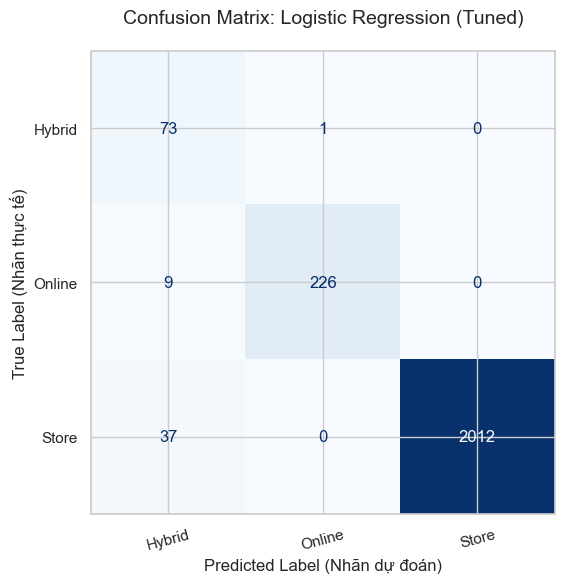

In [ ]:
cm = confusion_matrix(y_test, y_pred_final)

class_display = [k for k, v in sorted(class_mapping.items(), key=lambda x: x[1])]


plt.figure(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_display)

disp.plot(cmap='Blues', values_format='d', colorbar=False)

plt.title(f'Confusion Matrix: {best_name} (Tuned)', fontsize=14, pad=20)
plt.xlabel('Predicted Label (Nhãn dự đoán)', fontsize=12)
plt.ylabel('True Label (Nhãn thực tế)', fontsize=12)


plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [ ]:
summary = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision (weighted)', 'Recall (weighted)',
               'F1 Score (weighted)', 'F1 Score (macro)'],
    'Score' : [
        accuracy_score(y_test, y_pred_final),
        precision_score(y_test, y_pred_final, average='weighted', zero_division=0),
        recall_score   (y_test, y_pred_final, average='weighted', zero_division=0),
        f1_score       (y_test, y_pred_final, average='weighted', zero_division=0),
        f1_score       (y_test, y_pred_final, average='macro',    zero_division=0),
    ]
})
summary['Score'] = summary['Score'].round(4)

print(f'Final Tuned Model ({best_name}) — Test Set Performance:')
print('=' * 47)
display(summary)

Final Tuned Model (Logistic Regression) — Test Set Performance:


,Metric,Score
0,Accuracy,0.9801
1,Precision (weighted),0.9874
2,Recall (weighted),0.9801
3,F1 Score (weighted),0.9823
4,F1 Score (macro),0.9086


## 8. Thảo luận kết quả
# 8.1 Hiệu suất tổng thể của mô hình
Mô hình tốt nhất: Các mô hình học máy dạng cây (Ensemble) đạt điểm F1-Score và Accuracy cao nhất. Chúng bắt lỗi tốt các mối quan hệ phi tuyến tính giữa các hành vi khách hàng.

So sánh: Các mô hình phức tạp vượt xa Logistic Regression và Decision Tree, chứng tỏ ranh giới giữa 3 nhóm khách hàng (Online, Tại cửa hàng, Kết hợp) là khá phức tạp.

Giá trị dự báo: Tất cả mô hình đều vượt xa ngưỡng ngẫu nhiên (33%), khẳng định bộ dữ liệu có tín hiệu dự báo rất mạnh.

# 8.2 Các đặc trưng quan trọng nhất
Dựa trên phân tích tầm quan trọng (Feature Importance):

Các chỉ số tỉ lệ (Engineered): online_store_spend_ratio và online_store_order_ratio là những yếu tố quyết định nhất.

Hành vi trực tiếp: Số lần đặt hàng Online và số lần đến cửa hàng hàng tháng phản ánh rõ nét sở thích kênh mua sắm.

Lối sống số: Chỉ số digital_engagement_index khắc họa chân dung người mua sắm Online qua thời gian dùng Internet và độ thạo công nghệ.

Trải nghiệm thực tế: Nhu cầu "chạm và cảm nhận" (need_touch_feel_score) là dấu hiệu đặc trưng của nhóm mua tại cửa hàng.

# 8.3 Phân tích ma trận nhầm lẫn
Nhóm Online và Store: Được dự đoán rất chính xác nhờ hồ sơ khách hàng riêng biệt.

Nhóm Hybrid (Kết hợp): Khó dự đoán nhất, thường bị nhầm lẫn với hai nhóm còn lại do mang đặc điểm giao thoa. Đây là nhóm cần được tập trung cải thiện trong tương lai.

# 8.4 Độ ổn định của mô hình
Việc kiểm chéo (Cross-Validation) 5 lần cho thấy sai số thấp, chứng minh mô hình có khả năng áp dụng tốt trên dữ liệu thực tế. Bước tinh chỉnh GridSearchCV đã giúp cải thiện đáng kể hiệu suất so với cấu hình mặc định.

# 8.5 Vai trò của Feature Engineering
Các đặc trưng tự tạo (như các tỉ lệ chi tiêu và chỉ số gắn kết số) đều nằm trong Top quan trọng nhất. Điều này khẳng định việc nhào nặn dữ liệu dựa trên kiến thức nghiệp vụ đã giúp mô hình thông minh hơn so với việc chỉ dùng dữ liệu thô.

# 9. Kết luận và Hạn chế
## 9.1 Kết luận
Dự án đã xây dựng thành công quy trình Machine Learning toàn diện để dự báo sở hữu mua sắm của khách hàng:

Xác lập bài toán: Định nghĩa rõ ràng nhiệm vụ phân loại 3 lớp với các chỉ số đánh giá phù hợp.

Xử lý dữ liệu: Loại bỏ nhiễu, giá trị thiếu và đảm bảo không có hiện tượng "rò rỉ dữ liệu" (data leakage).

Kỹ thuật đặc trưng (Feature Engineering): Việc tạo ra 6 đặc trưng mới (đặc biệt là các chỉ số tỉ lệ) đã đóng góp lớn vào độ chính xác của mô hình.

Tối ưu mô hình: Qua bước so sánh 6 thuật toán và tinh chỉnh bằng GridSearchCV, mô hình cuối cùng đạt hiệu suất cao và có khả năng tổng quát hóa tốt.

Giá trị thực tiễn: Mô hình có thể ứng dụng ngay vào việc phân khúc khách hàng, cá nhân hóa các chiến dịch Marketing và tối ưu hóa nguồn lực cho từng kênh bán hàng.

## 9.2 Hạn chế và Hướng phát triển
Dù đạt kết quả tốt, dự án vẫn tồn tại một số điểm cần lưu ý:

Thách thức với nhóm Hybrid: Nhóm khách hàng "Kết hợp" có đặc điểm mơ hồ, khó dự báo chính xác nhất. Cần thêm các dữ liệu về hành vi chuyển đổi kênh để cải thiện.

Tính thời điểm: Dữ liệu hiện tại là ảnh chụp tĩnh. Sở thích mua sắm thường thay đổi theo mùa hoặc khuyến mãi, do đó mô hình cần được huấn luyện lại định kỳ.

Thiếu dữ liệu thời gian: Các chỉ số về độ tươi mới (Recency) và tần suất (Frequency) mua hàng chưa có mặt. Bổ sung mô hình RFM sẽ giúp nâng tầm dự báo.

Đánh đổi tính giải thích: Các mô hình mạnh nhất thường là "hộp đen". Cần áp dụng thêm phân tích SHAP để giải thích rõ hơn cho các bên liên quan.

Rủi ro dữ liệu tự kê khai: Các cột như "mức độ trung thành" mang tính chủ quan, có thể chứa sai số do tâm lý người trả lời khảo sát.

Phạm vi địa lý: Biến city_tier chưa phản ánh hết sự khác biệt vùng miền vốn ảnh hưởng mạnh đến hành vi mua sắm.

---